# Fall 2026 IAB Meeting Data Science/AI Tutorial and Workshop
#### Presented by the Leonard Lab
#### Tuesday, October 13th

In this tutorial workshop, you will learn how to:
1. Prepare a dataset for machine learning
2. Build a random forest classification model
3. Interpret the model's predictions for scientific gain


As industries rapidly adopt AI and machine learning (ML) to drive innovation, helping scientists overcome the machine learning learning curve is essential for maintaining a competitive edge. This hands-on workshop bridges that gap by teaching participants how to process and analyze complex scientific data using practical Python models. By mastering these foundational skills, researchers can **translate raw data into actionable insights** to accelerate both academic discoveries and real-world industrial advancements!

--------

## Introduction to Random Forest

### What is a random forest?
* Random forest, consists of a large number of individual decision trees that operate as an ensemble.
* Each individiual decision tree is trained on on various sub-samples of the dataset.
* Each individual tree in the random forest outputs one class prediction.
* The final output of a random forest is a majority vote among all of the trees.

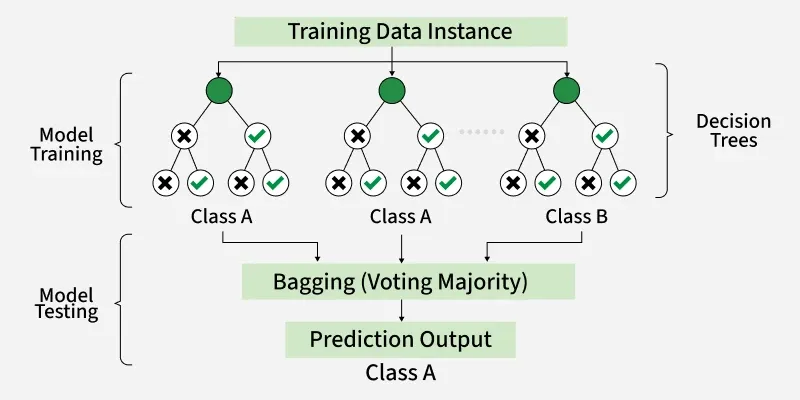

https://www.geeksforgeeks.org/machine-learning/random-forest-algorithm-in-machine-learning/

More information on Random Forest Can be found here: https://towardsdatascience.com/understanding-random-forest-58381e0602d2

---------------------

The first step is to mount your notebook to your google drive.

We will need packages for data manipulation and visualization. It is common practice to import these packages with shorthand names like "pd" or "np" to make coding faster.

Sci-kit Learn has out-of-the-box tools for setting up ML models:

SHapley Additive exPlanations (SHAP) is the package for which we will analyze model predictions to gather insights:

---------------

## Pre-Processing the Dataset

To work with a dataset, you must first import it. Pandas has a method (like a function) called read_csv() which

Always check the dataset for missing values or imbalanced classes.

Machine learning requires that you encode your labels and fill in NoneType/NaN entries:

We have pre-encoded the 'Structure' and 'Electrolyte' features using the scheme below to help the model have a better understanding of their physical bases:

<div style="display: flex; flex-wrap: wrap; gap: 30px; align-items: flex-start;">

<div>

| Structure | Enc | Structure | Enc |
| :--- | :--- | :--- | :--- |
| Not specified | 0 | Anodized Foil | 30 |
| other | 0 | Porous | 40 |
| Nanoparticle | 10 | Porous Thin Film | 40 |
| Nanoparticles | 10 | Porous, Oxide-derived | 50 |
| Nanoparticle/Nanorod | 10 | Porous, Oxide Derived | 50 |
| Core/Shell Nanoparticles | 10 | Oxide derived | 50 |
| Nanoparticles supported by nanosheets | 10 | Oxide derived, Polycrystalline | 50 |
| Thin film | 20 | Polycrystalline | 60 |
| Foil, Film | 30 | Cu-CI-ED (Polycrystalline) | 60 |
| Foil | 30 | Amorphous | 70 |

</div>

<div>

| Electrolyte | Enc | Electrolyte | Enc |
| :--- | :--- | :--- | :--- |
| Not specified | 0 | Cs based | 130 |
| Sodium Based | 10 | Acid | 140 |
| NaOH | 20 | phosphate buffer | 150 |
| NaClO4 | 30 | other aqueous | 160 |
| Na2SO4 | 40 | Acetonitrile | 170 |
| NaHCO3 | 50 | TBAPF6/MeCN | 180 |
| Bicarbonate | 60 | TBAPF6 | 190 |
| KHCO3 | 70 | TBAPF6/DMF | 200 |
| K2CO3 | 80 | DMF | 210 |
| KOH | 90 | other organic | 220 |
| KCl | 100 | Ionic Liquids | 230 |
| K2SO4 | 110 | YSZ | 240 |
| Potassium Based | 120 | other | 250 |

</div>

<div>

| Structure (One-Hot) | Enc | Structure (One-Hot) | Enc |
| :--- | :--- | :--- | :--- |
| other | 0 | Porous, Oxide-derived | 50 |
| Nanoparticle | 10 | Oxide derived, Polycrystalline | 50 |
| Thin film | 20 | Polycrystalline | 60 |
| Foil, Film | 30 | Amorphous | 70 |
| Porous | 40 | | |

</div>

</div>

ML models cannot work with missing (NoneType) entries in a dataset, so you must first check which columns need to be manually filled in. This is common for chemical applications where research is data-limited.

Now we can replace those values in each column with the column mean, median, mode, zero, or other meaningful value:

Below is a pre-written loop that, for each feature value, displays the percentage of entries which are non-zero. This gives you a sense of your data quality.

In [ ]:
#pre-written loop

print("Number of non-zero entries per column:\n")

def round_sig(x, sig=3):
    if pd.isna(x):
        return x
    return round(x, sig - int(np.floor(np.log10(abs(x)))) - 1)

num_rows = len(df)
for col in df.columns:
    count = np.count_nonzero(df[col])
    if count > 0:
        percent_nonzero = round_sig((count/num_rows)*100)
    else:
        percent_nonzero = 0.00
    print(f"{col}: \t {count} / {num_rows}, ({percent_nonzero}%)")

## Train Test Split

Our dataset will be split into 3 subsets: training, testing, and validation. ML algorithms like random forests use the training subset to regress rules dictating model predictions, while the validation and testing sets are put aside to check the model's predictability later.

But ML algorithms, including random forests, are stochastic, meaning they can be lucky or unlucky in their predictions. To eliminate this element and get a consistent model, we use k-fold cross validation, where k number of training and validation data subsets (called folds) are set aside to check multiple random forests' accuracies on making predictions. These scores are averaged to get a mean k-fold cross validation score.

Finally, once a reliable model is reached, we test it on the testing subset, like a final exam.

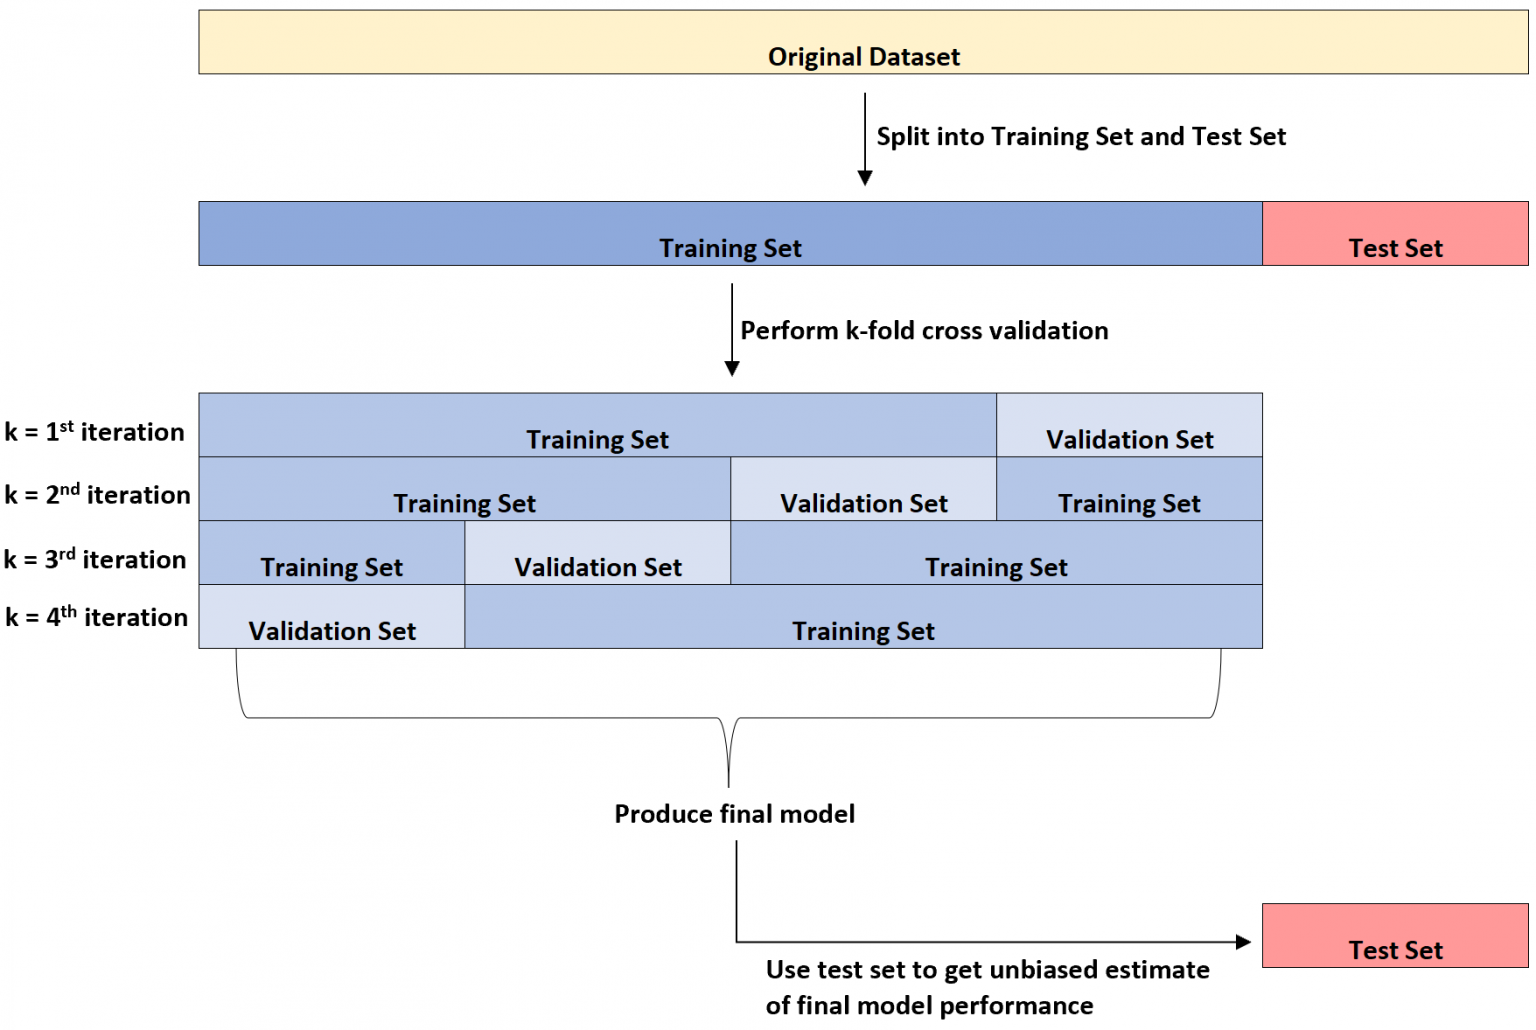

https://scales.arabpsychology.com/stats/what-is-the-difference-between-a-validation-set-and-a-test-set/

80-10-10 split means that 10% of the original data is set aside as training data, then 10% of the remaining training data is set aside as validation data.

(this results in it not being exactly 80-10-10, but it's close enough)

## Initializing the model

With the data partitioned we can now build our model. There are some decisions about "hyperparameters" that we need to make, including how big or deep our estimators are allowed to be. These have a direct impact on model fitting.

The link below is the documentation on sklearn's random forest classifier. It explains the hyperparameters which we have control of.

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

The loop below shows how models of low depth are underfit, but models of high depth become overfit. We need to design models which are in a sweet spot of being good at predicting, but not so conditioned by the training data that they perform poorly on unseen data.

Here is a resource with an in-depth explanation https://machinelearningmastery.com/overfitting-machine-learning-models/

In [ ]:
#pre-written loop

values = [i for i in range(1, 30)]
train_scores = []
test_scores = []

for i in values:
    model_cv = RandomForestClassifier(max_depth=i, random_state = 77, criterion=criterion, max_features=max_features)
    model_cv.fit(X_train, y_train)

    train_yhat = model_cv.predict(X_train)
    train_acc = accuracy_score(y_train, train_yhat)
    train_scores.append(train_acc)

    test_yhat = model_cv.predict(X_val)
    test_acc = accuracy_score(y_val, test_yhat)
    test_scores.append(test_acc)

plt.plot(values, train_scores, '-o', label='Train')
plt.plot(values, test_scores, '-o', label='Test')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

Along with initializing the forest, we may also initialize the COdeCarbon emissions tracker.

It's best practice to put the tracker start and stop statements around the model fitting instruction.

## Evaluating the model

Once your model is tuned and trained, it's time to benchmark it! We want to know how precise and accurate it is at making predictions before we do anything else.

These are the common metrics we use to evaluate binary classifiers, where TP represents the number of True Positive predictions, FP represents the number of False Positive predictions, TN represents the number of True Negative predictions, and FN represents the number of false negative predictions.

Accuracy = $ \frac{\text{TP} + \text{TN}}{\text{TP} + \text{FN} + \text{TN} + \text{FP}} $

Precision = $ \frac{\text{TP}}{\text{TP+FP}}$

Recall = $ \frac{\text{TP}}{\text{TP+FN}} $

F1 = $ 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} \times{\text{Recall}}} = \frac{\text{TP} + \text{TP}}{\text{TP} + \text{FN} + \text{TP} + \text{FP}} $

Here you can see that F1 score is like accuracy, but for only one class (denoted the positive class). Each class has its own F1 score because either class can be considered the positive class.


A nice way of visualizing these metrics is by using a confusion matrix, which is a plot of the model's predictions vs the actual class labels.

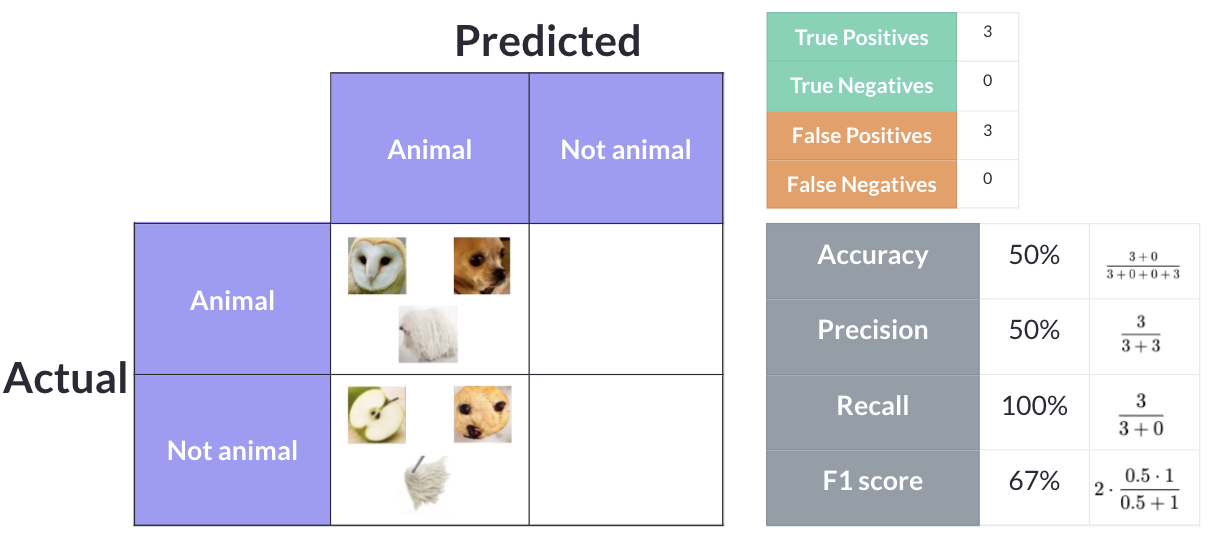

https://labelf.ai/blog/what-is-accuracy-precision-recall-and-f1-score

In [ ]:
#pre-written plot

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=[product_A, product_B],
            yticklabels=[product_A, product_B])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

But these results are for one tuned random forest. To get a more consistent idea of how well our data is being predicted upon, we need to perform k-fold cross validation.

Some machine learning models are known as "black box" because we can't easily extract their reasoning behind making predictions. Shallow learning models are different in that you can interpret their decision making processes in a few different ways. One way to do this on a feature-by-feature basis is called SHAP.

SHapley Additive exPlanations (SHAP) reveals what feature values are encouraging model classifications using game theory. It does so by treating each feature in a machine learning model as a "player" in a cooperative game, where the model's prediction is the total payout.

The results of this analysis can be visualized by what is called a beeswarm plot, shown below. If scientists compare these results with literature and intuition, new chemical insights can be extracted!

**Here is how to read a SHAP beeswarm plot!**

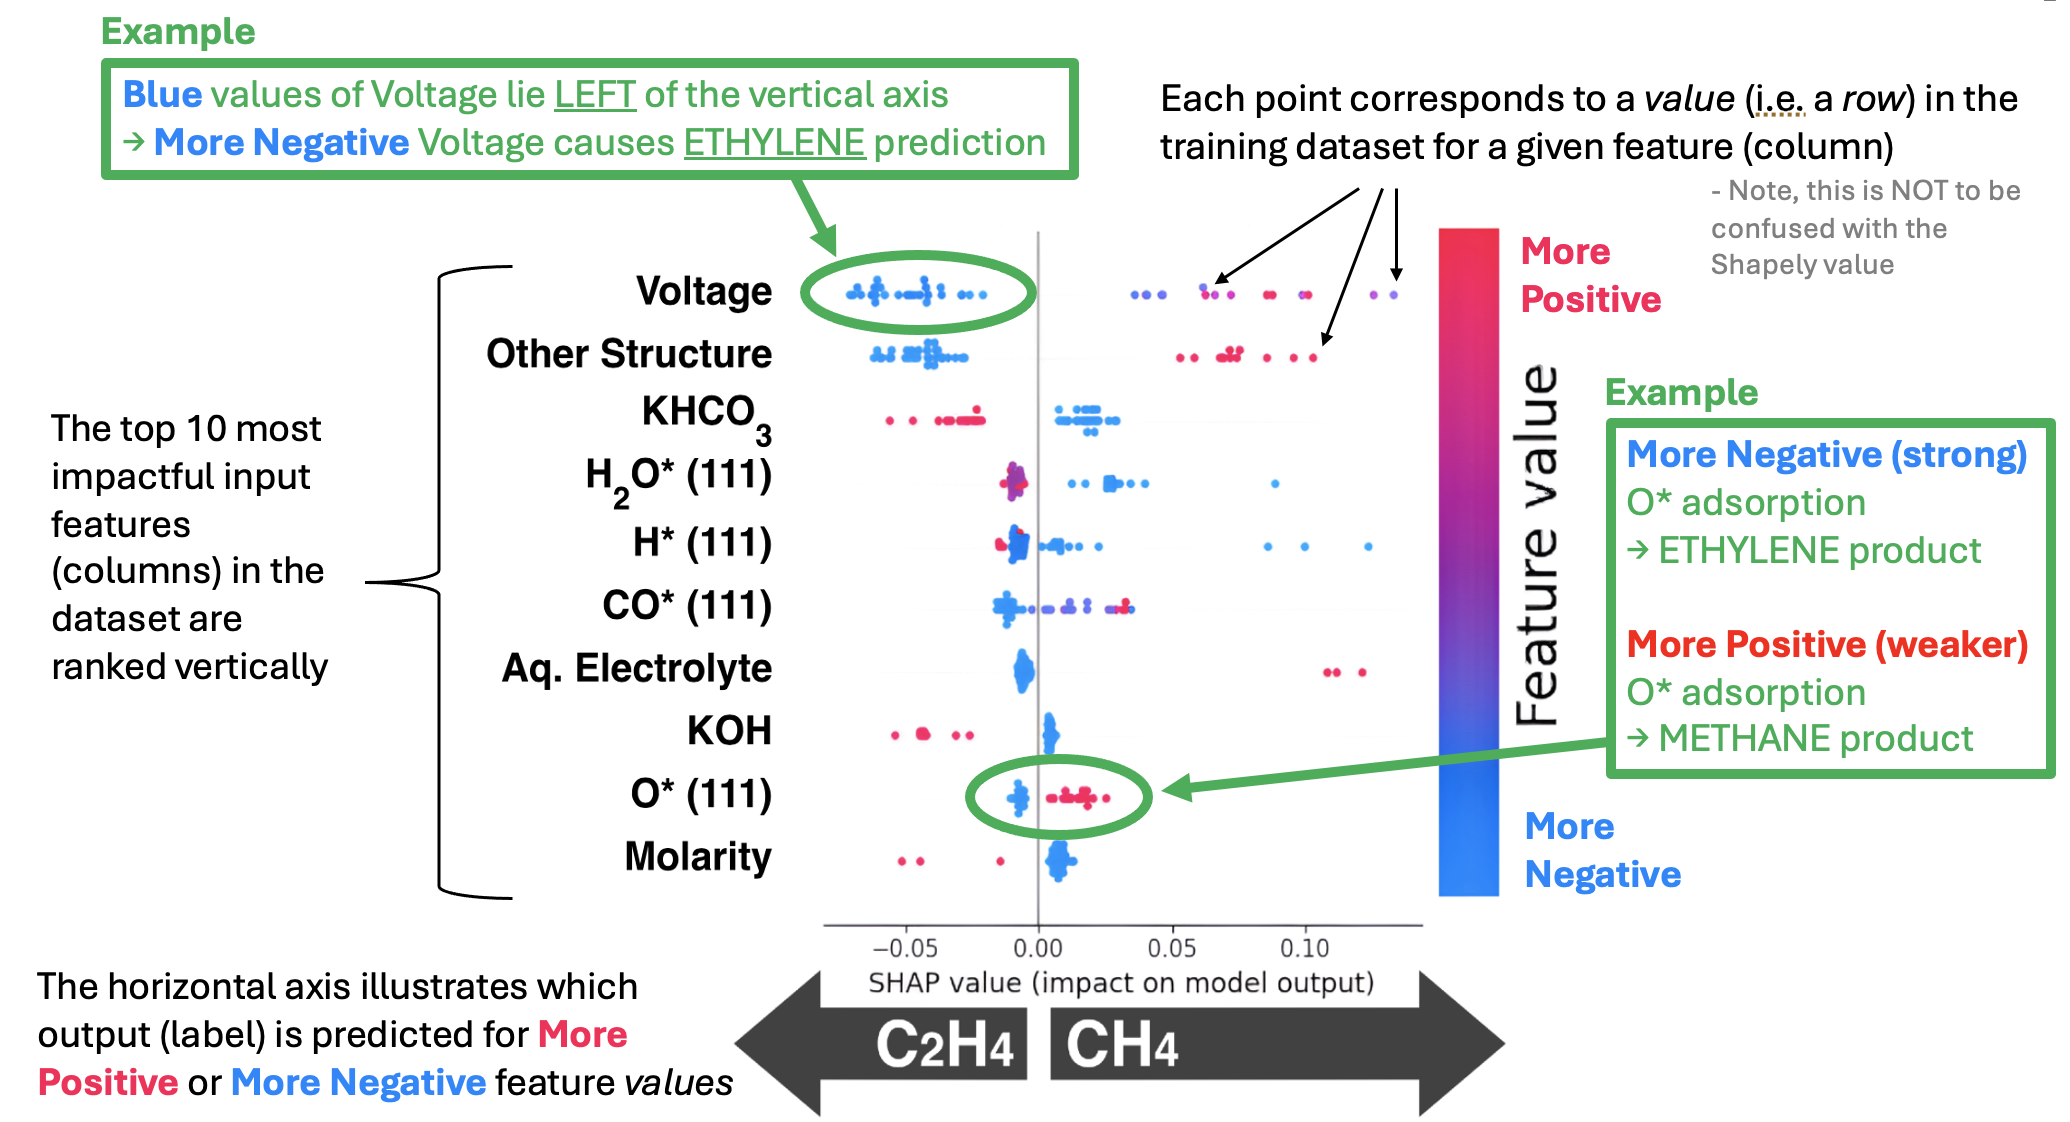

Another helpful guide: https://www.aidancooper.co.uk/a-non-technical-guide-to-interpreting-shap-analyses/

SHAP determines feature importance by isolating individual features a few at a time. However, since ML models can become confused by zero or NaN data, SHAP needs something called a masker to effectively hide remaining features during these tests. The masker creates a background dataset of realistic values to substitute for those absent features rather than using entries of zero or NaN.

Let's create the masker and train our SHAP explainers!

Now, plot it and interpret the results!

Points lying left of the vertical axis indicate values that caused model predictions of class "0". Points on the right were values that caused the model to predict "1".